In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Load Dataset

In [ ]:
import pandas as pd
df = pd.read_csv("/content/retail_sales_eda_dataset_50_rows (2).csv")

Display first 5 rows

In [ ]:
print(df.head())

   Order_ID     City     Category     Product  Unit_Price  Quantity  \
0         1  Chennai  Electronics  Headphones      1500.0       2.0   
1         2   Trichy     Clothing     T-Shirt       500.0       3.0   
2         3  Madurai      Grocery    Rice Bag       900.0       2.0   
3         4      NaN  Electronics       Mouse       700.0       2.0   
4         5    Salem     Clothing       Jeans      1200.0       1.0   

   Total_Sales Payment_Method  
0       3000.0            UPI  
1       1500.0           Cash  
2       1800.0           Card  
3       1400.0            UPI  
4       1200.0           Card  


display last 5 rows

In [ ]:
print(df.tail())

    Order_ID        City     Category     Product  Unit_Price  Quantity  \
45        46     Chennai  Electronics     Charger       400.0       3.0   
46        47      Trichy     Clothing       Jeans      1200.0       1.0   
47        48     Madurai      Grocery  Tea Powder       250.0       3.0   
48        49  Coimbatore  Electronics     Speaker      2200.0       1.0   
49        50       Salem     Clothing       Kurti       850.0       2.0   

    Total_Sales Payment_Method  
45       1200.0            UPI  
46       1200.0           Card  
47        750.0           Card  
48       2200.0            UPI  
49       1700.0           Card  


In [ ]:
print(df.head(8))

   Order_ID     City     Category      Product  Unit_Price  Quantity  \
0         1  Chennai  Electronics   Headphones      1500.0       2.0   
1         2   Trichy     Clothing      T-Shirt       500.0       3.0   
2         3  Madurai      Grocery     Rice Bag       900.0       2.0   
3         4      NaN  Electronics        Mouse       700.0       2.0   
4         5    Salem     Clothing        Jeans      1200.0       1.0   
5         6  Chennai      Grocery  Cooking Oil       180.0       5.0   
6         7   Trichy          NaN     Keyboard      1100.0       1.0   
7         8  Madurai     Clothing        Kurti       850.0       2.0   

   Total_Sales Payment_Method  
0       3000.0            UPI  
1       1500.0           Cash  
2       1800.0           Card  
3       1400.0            UPI  
4       1200.0           Card  
5        900.0           Cash  
6       1100.0            UPI  
7       1700.0           Card  


display numbers of rows and columns

In [ ]:
print("dataset shape:",df.shape)

dataset shape: (50, 8)


dataset info

In [ ]:
print(df.info)

<bound method DataFrame.info of     Order_ID        City     Category      Product  Unit_Price  Quantity  \
0          1     Chennai  Electronics   Headphones      1500.0       2.0   
1          2      Trichy     Clothing      T-Shirt       500.0       3.0   
2          3     Madurai      Grocery     Rice Bag       900.0       2.0   
3          4         NaN  Electronics        Mouse       700.0       2.0   
4          5       Salem     Clothing        Jeans      1200.0       1.0   
5          6     Chennai      Grocery  Cooking Oil       180.0       5.0   
6          7      Trichy          NaN     Keyboard      1100.0       1.0   
7          8     Madurai     Clothing        Kurti       850.0       2.0   
8          9  Coimbatore      Grocery        Sugar        50.0      10.0   
9         10       Salem  Electronics      Speaker         NaN       1.0   
10        11     Chennai     Clothing        Saree      1800.0       1.0   
11        12      Trichy      Grocery  Wheat Flour      

sample

In [ ]:
print(df.sample(9))

    Order_ID        City     Category      Product  Unit_Price  Quantity  \
9         10       Salem  Electronics      Speaker         NaN       1.0   
49        50       Salem     Clothing        Kurti       850.0       2.0   
40        41     Chennai     Clothing        Saree      1800.0       1.0   
34        35       Salem     Clothing       Salwar      1400.0       1.0   
4          5       Salem     Clothing        Jeans      1200.0       1.0   
26        27      Trichy      Grocery  Wheat Flour        70.0       8.0   
28        29  Coimbatore     Clothing          NaN       350.0       4.0   
32        33         NaN      Grocery     Biscuits        30.0      12.0   
46        47      Trichy     Clothing        Jeans      1200.0       1.0   

    Total_Sales Payment_Method  
9        2200.0            UPI  
49       1700.0           Card  
40       1800.0           Card  
34       1400.0           Card  
4        1200.0           Card  
26        560.0           Cash  
28      

discribe

In [ ]:
print(df.describe())

       Order_ID   Unit_Price   Quantity  Total_Sales
count  50.00000    49.000000  48.000000    49.000000
mean   25.50000   805.102041   3.166667  1403.469388
std    14.57738   649.368676   2.770155   638.965802
min     1.00000    30.000000   1.000000   300.000000
25%    13.25000   250.000000   1.000000   900.000000
50%    25.50000   700.000000   2.000000  1400.000000
75%    37.75000  1200.000000   3.250000  1800.000000
max    50.00000  2500.000000  12.000000  3000.000000


check missing values

In [ ]:
print(df.isnull().sum())

Order_ID          0
City              2
Category          1
Product           1
Unit_Price        1
Quantity          2
Total_Sales       1
Payment_Method    2
dtype: int64


In [ ]:
print("total missing values:",df.isnull().sum().sum())

total missing values: 10


In [ ]:
missing_percent=(df.isnull().sum()/ len(df))*100
print(missing_percent)

Order_ID          0.0
City              4.0
Category          2.0
Product           2.0
Unit_Price        2.0
Quantity          4.0
Total_Sales       2.0
Payment_Method    4.0
dtype: float64


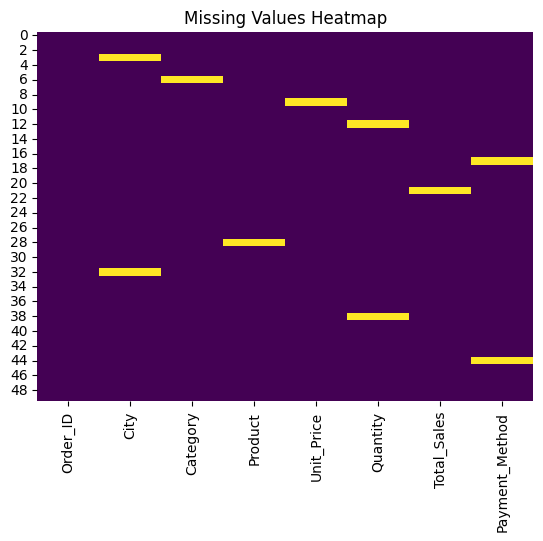

In [ ]:
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Values Heatmap")
plt.show()

fill missing values using mean

In [ ]:
cat_cols = df.select_dtypes(include=["object", "category"]).columns

for col in cat_cols:
    if df[col].isnull().any():
        mode_value = df[col].mode()
        if not mode_value.empty:
            df[col] = df[col].fillna(mode_value[0])


In [ ]:
print("\nTotal missing values:")
print(df.isnull().sum().sum())



Total missing values:
0


check duplicates

In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [ ]:
print(df[df.duplicated()])

Empty DataFrame
Columns: [Order_ID, City, Category, Product, Unit_Price, Quantity, Total_Sales, Payment_Method]
Index: []


In [ ]:
df = df.drop_duplicates()

analyse columns

In [ ]:
print(df.dtypes)

Order_ID            int64
City               object
Category           object
Product            object
Unit_Price        float64
Quantity          float64
Total_Sales       float64
Payment_Method     object
dtype: object


In [ ]:
print(df.nunique())

Order_ID          50
City               5
Category           3
Product           25
Unit_Price        21
Quantity           8
Total_Sales       19
Payment_Method     3
dtype: int64


In [ ]:
cat_cols = df.select_dtypes(include=["object", "category"]).columns

for col in cat_cols:
    print(f"\nColumn: {col}")
    print(df[col].value_counts().head(10))



Column: City
City
Chennai       10
Trichy        10
Salem         10
Madurai        9
Coimbatore     9
Name: count, dtype: int64

Column: Category
Category
Clothing       17
Electronics    16
Grocery        16
Name: count, dtype: int64

Column: Product
Product
T-Shirt        3
Cooking Oil    3
Rice Bag       3
Mouse          3
Jeans          3
Kurti          3
Charger        3
Saree          3
Speaker        3
Tea Powder     3
Name: count, dtype: int64

Column: Payment_Method
Payment_Method
UPI     17
Card    17
Cash    14
Name: count, dtype: int64


Numerical Columns

In [ ]:
# Check for missing values in the DataFrame
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values)

print("\nTotal missing values in the dataset:", missing_values.sum())

Missing values per column:
Order_ID          0
City              2
Category          1
Product           1
Unit_Price        1
Quantity          2
Total_Sales       1
Payment_Method    2
dtype: int64

Total missing values in the dataset: 10


In [ ]:

# Replace missing values

# 1. Numerical columns: Replace with Median
numerical_columns = df.select_dtypes(include=['number']).columns

for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

# 2. Categorical columns: Replace with Mode
categorical_columns = df.select_dtypes(include=['object', 'category']).columns

for col in categorical_columns:
    if df[col].isnull().sum() > 0 and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

# 3. Check missing values again
print("Missing values after replacement:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())


Missing values after replacement:
Order_ID          0
City              0
Category          0
Product           0
Unit_Price        0
Quantity          0
Total_Sales       0
Payment_Method    0
dtype: int64

Total missing values: 0


Data visualization
A.Histogram - numerical data distrubtion

In [ ]:
import pandas as pd

df = pd.read_csv("/content/retail_sales_eda_dataset_50_rows (2).csv")

numerical_columns = df.select_dtypes(include=['int64', 'float64'])

print("Numerical Columns:")
print(numerical_columns.columns.tolist())

print(numerical_columns.head())

Numerical Columns:
['Order_ID', 'Unit_Price', 'Quantity', 'Total_Sales']
   Order_ID  Unit_Price  Quantity  Total_Sales
0         1      1500.0       2.0       3000.0
1         2       500.0       3.0       1500.0
2         3       900.0       2.0       1800.0
3         4       700.0       2.0       1400.0
4         5      1200.0       1.0       1200.0


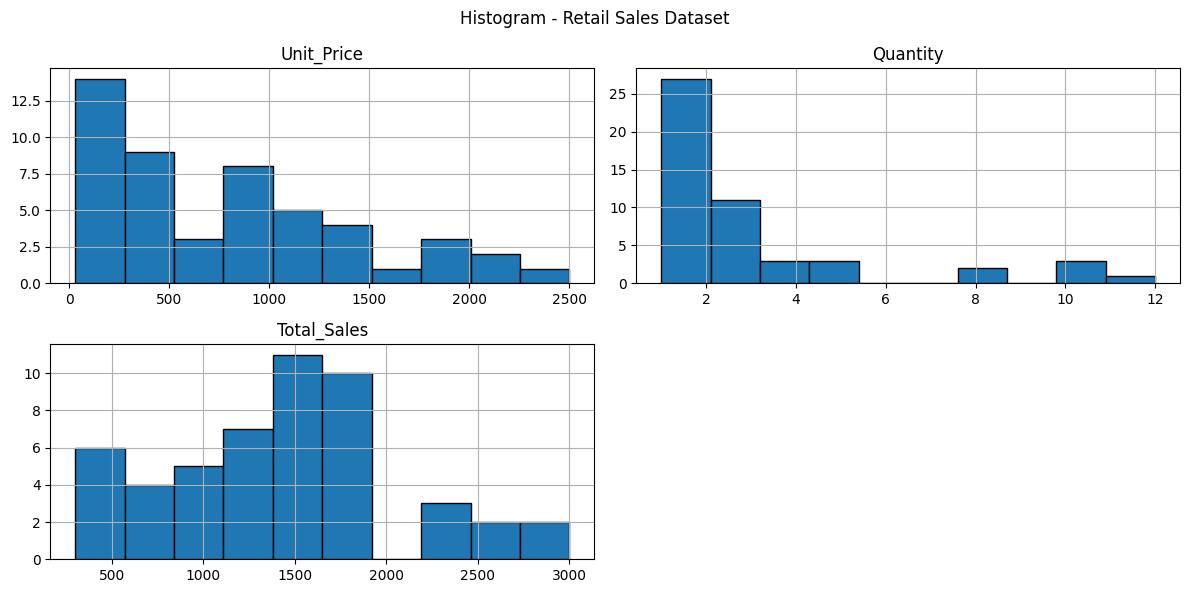

In [ ]:
num_cols = ['Unit_Price', 'Quantity', 'Total_Sales']

df[num_cols].hist(
    figsize=(12, 6),
    bins=10,
    edgecolor='black'
)

plt.suptitle("Histogram - Retail Sales Dataset")
plt.tight_layout()
plt.show()

Boxplot

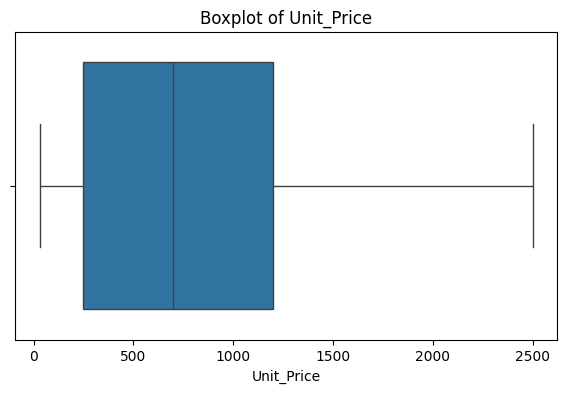

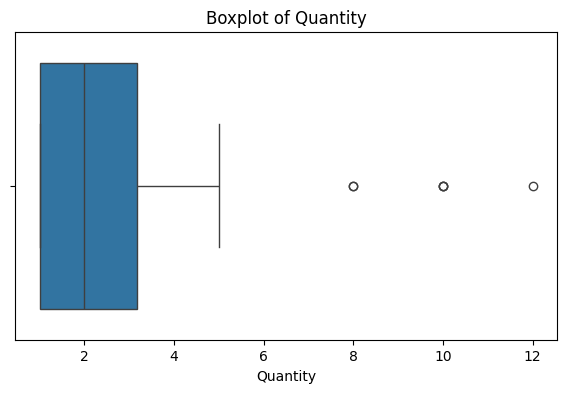

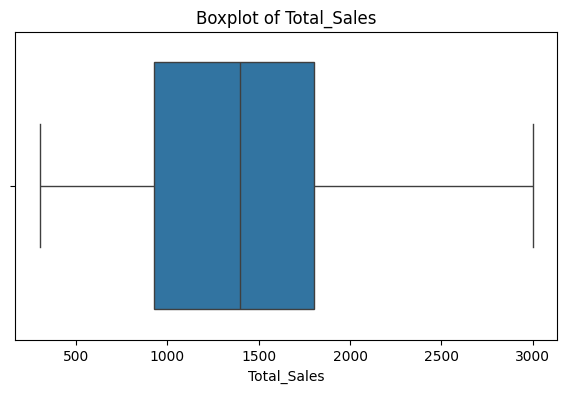

In [ ]:
for col in num_cols:
    plt.figure(figsize=(7, 4))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.show()

countplot

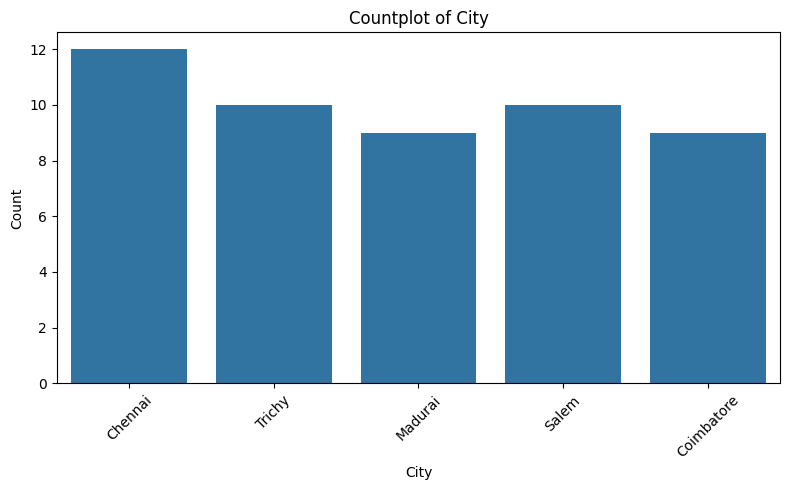

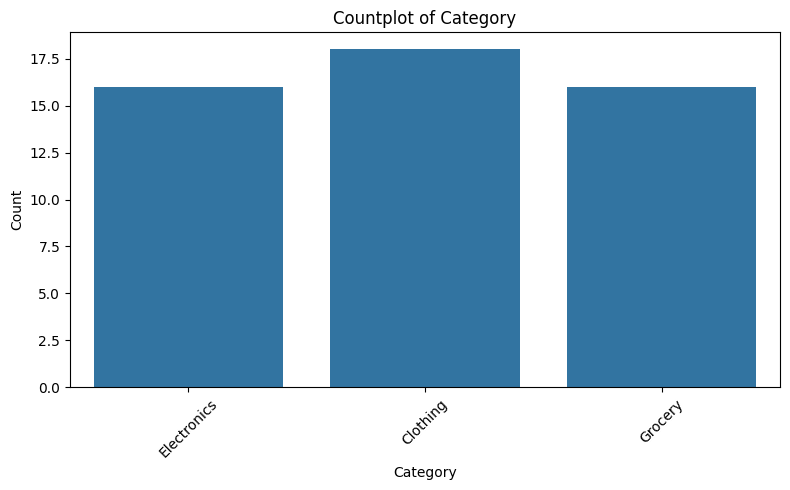

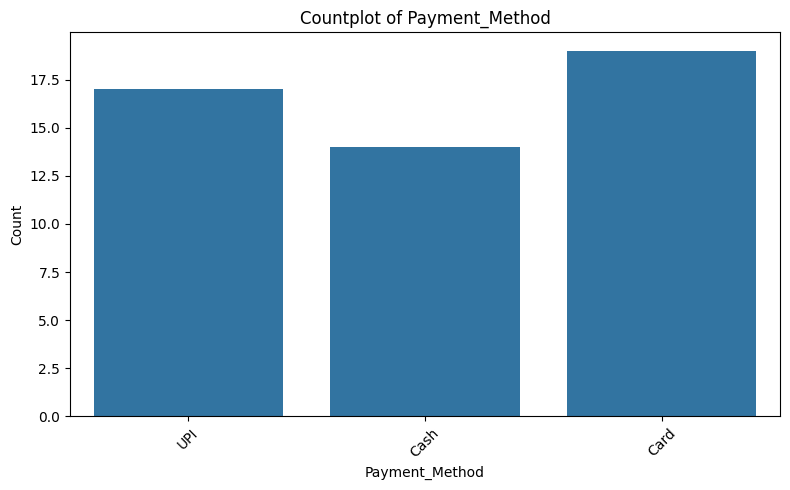

In [ ]:
cat_cols = ['City', 'Category', 'Payment_Method']

for col in cat_cols:
    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df,
        x=col
    )

    plt.title(f"Countplot of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

correlation headmap

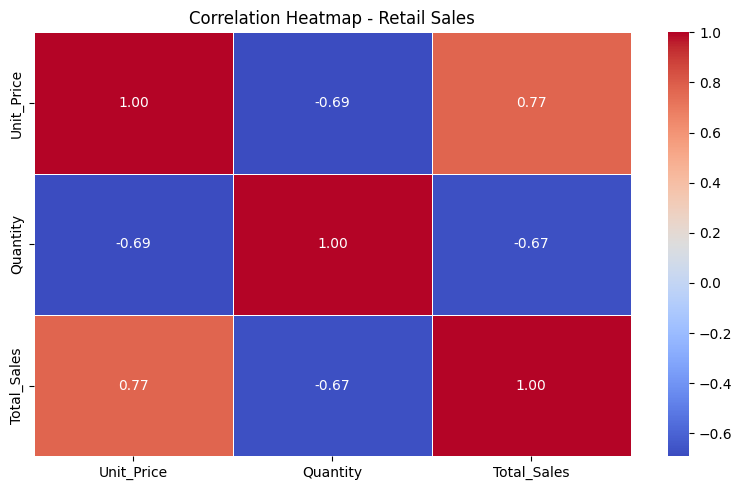

In [ ]:
plt.figure(figsize=(8, 5))

corr = df[num_cols].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap - Retail Sales")
plt.tight_layout()
plt.show()

scatter plot

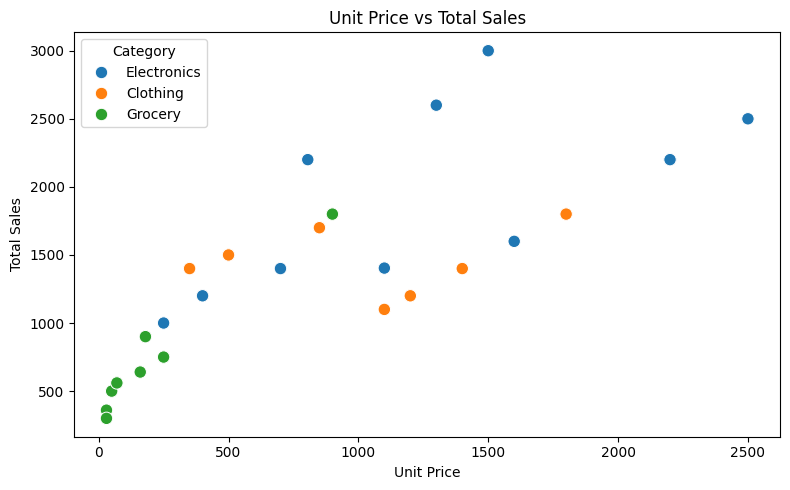

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Unit_Price',
    y='Total_Sales',
    hue='Category',
    s=80
)

plt.title("Unit Price vs Total Sales")
plt.xlabel("Unit Price")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

pie chart

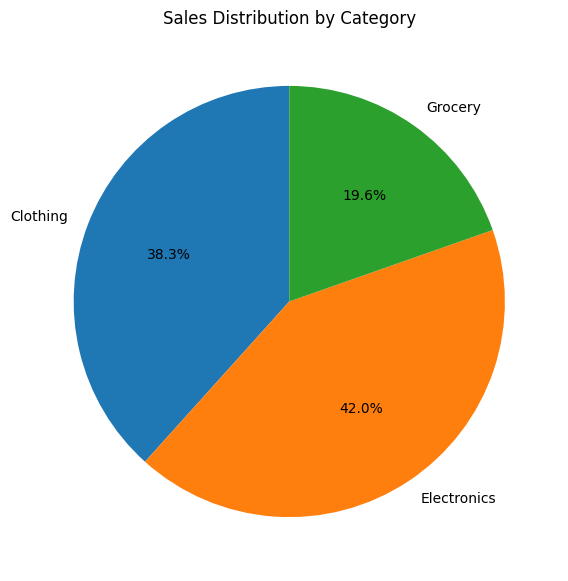

In [ ]:
import matplotlib.pyplot as plt

sales_by_category = df.groupby('Category')['Total_Sales'].sum()

plt.figure(figsize=(7, 7))

plt.pie(
    sales_by_category,
    labels=sales_by_category.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Sales Distribution by Category")
plt.show()